In [1]:
from linear_bai_utils import *
from linear_bai_as_utils import *
from weights_utils import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns

from sklearn.preprocessing import normalize

In [2]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    #N = 10000
    #p = 10
    theta = scale*(2*np.random.rand(p)-1)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

In [11]:
x, y, theta = gen_data(1000, p=2, scale=20)
m, d = x.shape
prob_dict = {
        "m": m,
        "d": d,
        "x": x,
        "theta": theta,
      }

prob = linear_discover(**prob_dict)
solver = lazy_TS(prob, laziness_factor=2)
reg, rwd, best, tau = solver.run(996, 0.9, 1)
tau, best == prob.best_arm

(nan, True)

In [17]:
prob_dict = {
        "m": m,
        "d": d,
        "x": x,
        "theta": theta,
      }

prob_as = linear_discover_as(**prob_dict)
solver_as = lazy_TS_as(prob_as, laziness_factor=2)
reg, rwd, best, tau = solver_as.run(996, 0.05, 1)
tau, best == prob_as.best_arm

(nan, True)

In [15]:
solver_as.prob.actions

[633,
 877,
 881,
 10,
 587,
 385,
 930,
 534,
 837,
 940,
 555,
 503,
 591,
 429,
 512,
 253,
 578,
 115,
 107,
 377,
 221,
 616,
 926,
 100,
 213,
 817,
 492,
 244,
 925,
 596,
 380,
 277,
 305,
 89,
 875,
 771,
 324,
 281,
 896,
 883,
 595,
 7,
 448,
 425,
 438,
 757,
 751,
 282,
 37,
 434,
 933,
 237,
 475,
 388,
 382,
 972,
 384,
 441,
 907,
 105,
 891,
 473,
 157,
 978,
 404,
 536,
 494,
 204,
 780,
 669,
 29,
 440,
 517,
 605,
 683,
 325,
 124,
 675,
 601,
 309,
 737,
 560,
 782,
 435,
 561,
 580,
 255,
 911,
 652,
 447,
 452,
 24,
 696,
 826,
 647,
 708,
 18,
 542,
 774,
 210,
 488,
 232,
 658,
 207,
 809,
 397,
 41,
 485,
 661,
 444,
 655,
 474,
 493,
 310,
 831,
 998,
 946,
 251,
 969,
 879,
 409,
 927,
 527,
 35,
 320,
 76,
 180,
 781,
 278,
 58,
 182,
 187,
 999,
 729,
 254,
 962,
 950,
 752,
 402,
 482,
 908,
 410,
 428,
 52,
 386,
 273,
 664,
 548,
 392,
 32,
 711,
 636,
 735,
 785,
 532,
 256,
 200,
 549,
 996,
 26,
 987,
 167,
 399,
 401,
 13,
 301,
 576,
 162,
 263,
 9

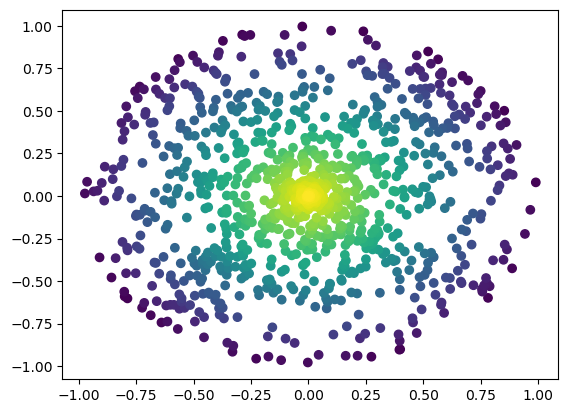

In [13]:
plt.scatter(x[np.argsort(np.linalg.norm(x,axis=1))[::-1], 0],
x[np.argsort(np.linalg.norm(x,axis=1))[::-1], 1], c=np.arange(1000))

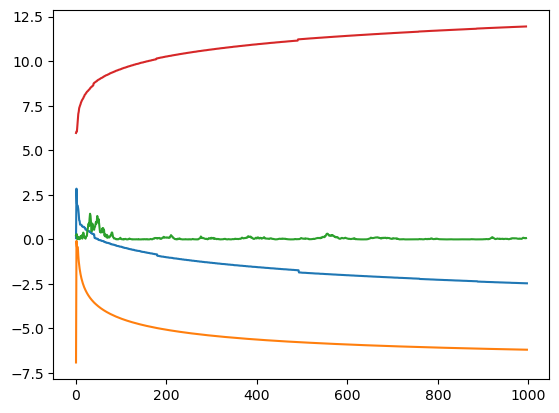

In [106]:
plt.plot(np.log([min(max(np.linalg.eigvals(np.linalg.pinv(x))),20) for x in np.cumsum(solver.prob.x[solver.prob.actions][:, :, None] @ solver.prob.x[solver.prob.actions][:,None], 0)]))
plt.plot(np.log([0.001+min(np.linalg.eigvals(np.linalg.pinv(x))) for x in np.cumsum(solver.prob.x[solver.prob.actions][:, :, None] @ solver.prob.x[solver.prob.actions][:,None], 0)]))
plt.plot(solver.Z_t)
plt.plot(solver.beta_t)

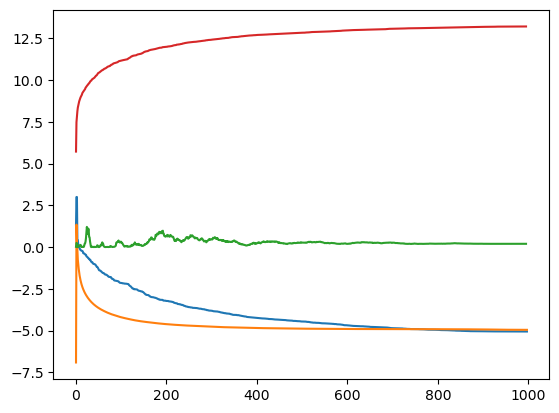

In [107]:
plt.plot(np.log([min(max(np.linalg.eigvals(np.linalg.pinv(x))),20) for x in np.cumsum(solver_as.prob.x[solver_as.prob.actions][:, :, None] @ solver_as.prob.x[solver_as.prob.actions][:,None], 0)]))
plt.plot(np.log([0.001+min(np.linalg.eigvals(np.linalg.pinv(x))) for x in np.cumsum(solver_as.prob.x[solver_as.prob.actions][:, :, None] @ solver_as.prob.x[solver_as.prob.actions][:,None], 0)]))
plt.plot(solver_as.Z_t)
plt.plot(solver_as.beta_t)


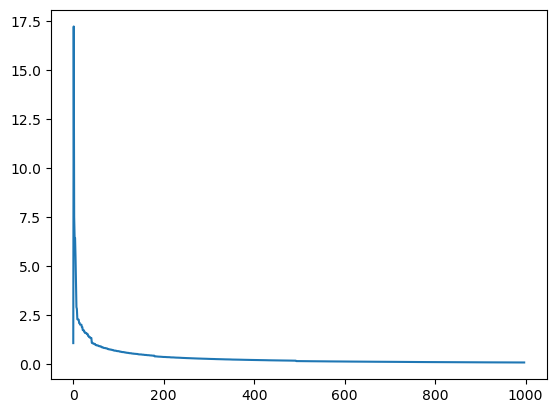

In [108]:
plt.plot([max(np.linalg.eigvals(np.linalg.pinv(x))) for x in np.cumsum(solver.prob.x[solver.prob.actions][:, :, None] @ solver.prob.x[solver.prob.actions][:,None], 0)])


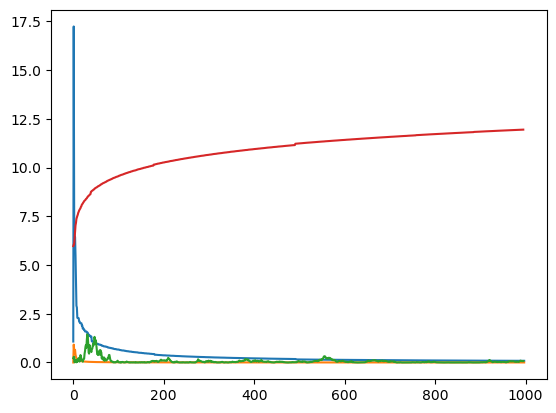

In [109]:
plt.plot([max(np.linalg.eigvals(np.linalg.pinv(x))) for x in np.cumsum(solver.prob.x[solver.prob.actions][:, :, None] @ solver.prob.x[solver.prob.actions][:,None], 0)])
plt.plot([min(np.linalg.eigvals(np.linalg.pinv(x))) for x in np.cumsum(solver.prob.x[solver.prob.actions][:, :, None] @ solver.prob.x[solver.prob.actions][:,None], 0)])
plt.plot(solver.Z_t)
plt.plot(solver.beta_t)

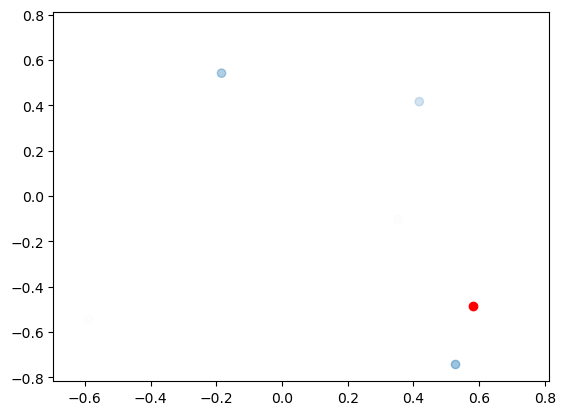

In [71]:
i=10
mask = solver.prob.mask_mat_hist[i]
design = solver.design_hist[i]
plt.scatter(solver.prob.x[~mask,0],
            solver.prob.x[~mask,1],
            alpha=design)

plt.scatter(solver.prob.x[solver.prob.best_arm,0],
            solver.prob.x[solver.prob.best_arm,1],
            c='r')

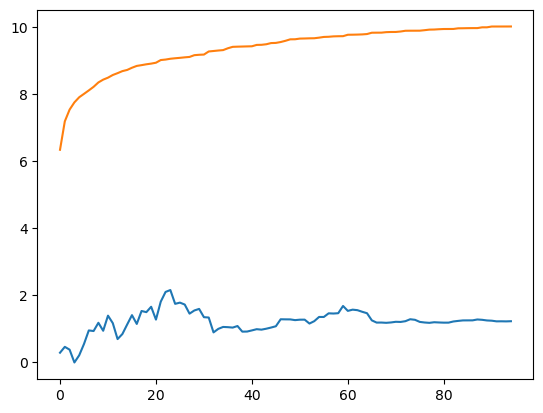

In [18]:
plt.plot(solver.Z_t)
plt.plot(solver.beta_t)

In [88]:
solver.A

array([[12.77868509,  9.09141878],
       [ 9.09141878, 22.25513682]])

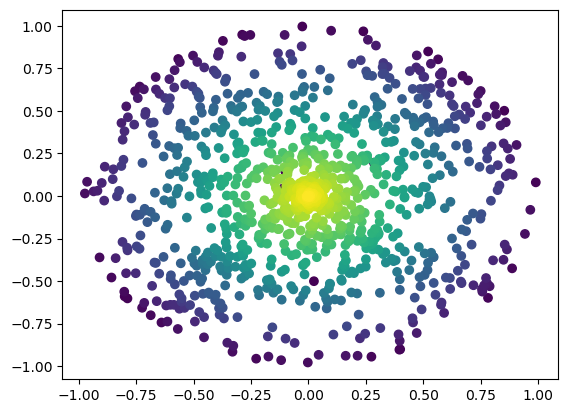

In [14]:
plt.scatter(solver.prob.x[solver_as.prob.actions,0],
            solver.prob.x[solver_as.prob.actions,1],
            c=np.arange(998))

In [25]:
tau_list1 = []
succ_list1 = []

tau_list2 = []
succ_list2 = []
for i in trange(10):
    x, y, theta = gen_data(1000, p=2, scale=10)
    m, d = x.shape 
    prob_dict = {
            "m": m,
            "d": d,
            "x": x,
            "theta": theta,
          }
    
    prob = linear_discover(**prob_dict)
    solver = lazy_TS(prob, laziness_factor=1)
    reg, rwd, best, tau = solver.run(1000, 0.05, 1)
    
    tau_list1.append(tau)
    succ_list1.append(best == prob.best_arm)

    prob_as = linear_discover_as(**prob_dict)
    
    solver_as = lazy_TS_as(prob_as, laziness_factor=1)
    reg, rwd, best, tau = solver_as.run(996, 0.05, 1)
        
    tau_list2.append(tau)
    succ_list2.append(best == prob_as.best_arm)


100%|███████████████████████████████████████████| 10/10 [15:30<00:00, 93.01s/it]


In [ ]:
(np.mean([1000 if np.isnan(x) else x for x in tau_list1]),
np.mean([1000 if np.isnan(x) else x for x in tau_list2]))

(489.7, 490.3)

In [27]:
tau_list1, tau_list2

([52, 249, 411, nan, 203, 95, nan, 858, nan, 29],
 [34, 309, 573, 323, 286, 343, nan, nan, nan, 35])

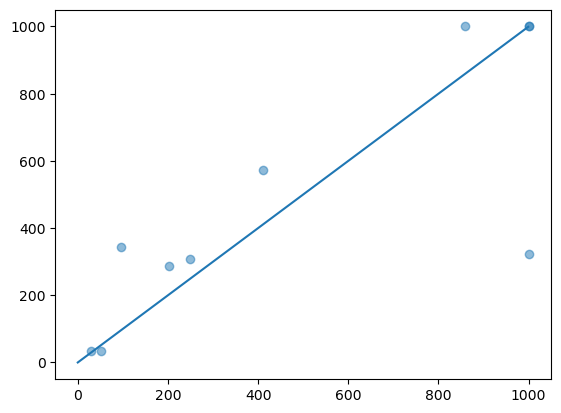

In [28]:
plt.scatter([1000 if np.isnan(x) else x for x in tau_list1],
[1000 if np.isnan(x) else x for x in tau_list2], alpha=.5)
plt.plot(range(1000))


In [29]:
(np.mean(succ_list1),
np.mean(succ_list2))

(1.0, 1.0)

In [43]:
(np.mean(succ_list1),
np.mean(succ_list2))

(0.9, 1.0)

In [40]:
(np.mean(succ_list1),
np.mean(succ_list2))

(1.0, 1.0)

In [46]:
(np.mean(succ_list1),
np.mean(succ_list2))

(1.0, 1.0)

In [4]:
T_max, delta = 100, 0.05
solver.delta = delta
solver.prob.refresh()
solver.prob.get_mask()
        
        #temp = np.zeros(self.prob.d)
solver.design = np.ones(solver.prob.m)
solver.design /= solver.design.sum()
        
solver.c2 = (1+solver.u) * (solver.prob.sigma**2)
solver._build_A0()
tau = np.nan

IndexError: boolean index did not match indexed array along dimension 0; dimension is 0 but corresponding boolean dimension is 1000

In [42]:
t = 0

In [43]:
action = solver._sampling_rule1(t)
r, _ = solver.prob.take_action(action)

In [44]:
prev_mask = solver.prob.mask_mat.copy()
_ = solver.prob.get_mask()
            

In [46]:
action_desgin = np.where(~(prev_mask == solver.prob.mask_mat)[~prev_mask])[0][0]
action_desgin

749

In [48]:
solver.design = np.delete(solver.design, action_desgin, 0)
solver.design /= solver.design.sum()
solver.design

array([0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100301,
       0.00100301, 0.00100301, 0.00100301, 0.00100301, 0.00100

(963, 963)

In [50]:
solver.update_posterior(action, r)

array([-11.11886342,  -5.06692575])

In [51]:
solver.best_arm_hat

962

In [54]:
np.argmax(solver.mean_hat)

962

In [55]:
np.argmax(solver.mean_hat[~solver.prob.mask_mat])

959

In [58]:
solver._Z(1)

0

In [59]:
solver.prob.actions

[868, 33, 750]

In [64]:
solver.best_arm_hat

962

In [63]:
np.max(gaps), np.max(gaps[~solver.prob.mask_mat])

(23.692256875427642, 23.692256875427642)

In [67]:
np.argmax(rewards)

962

In [62]:
x_t = solver.prob.x[~solver.prob.mask_mat]
rewards = solver.prob.x @ solver.theta_hat
gaps = rewards[solver.best_arm_hat] - rewards

In [14]:


gaps = gaps[~solver.prob.mask_mat]
best_arm_hat_ = np.argmax(gaps)
gaps = np.delete(gaps, best_arm_hat_, 0)
gaps

array([0.03423825, 0.13240343, 0.01249757, 0.14343057, 0.10577533,
       0.        , 0.1182598 ])

In [25]:
x_t = solver.prob.x[~solver.prob.mask_mat]
rewards = solver.prob.x @ solver.theta_hat
gaps = rewards[solver.best_arm_hat] - rewards
gaps = gaps[~solver.prob.mask_mat]
best_arm_hat_ = np.argmax(gaps)
gaps = np.delete(gaps, best_arm_hat_, 0)
gaps = gaps.reshape(len(gaps), 1)
if np.any(gaps == 0):
    return 0
Y = self.prob.x[self.best_arm_hat, :] - self.prob.x
Y = Y[~self.prob.mask_mat]
Y = np.delete(Y, best_arm_hat_, 0)
Y = (1/gaps)*Y
_I = np.ones((self.prob.d, 1))
#design = self.prob.T
design = t * self.design
A_inv = np.linalg.pinv(x_t.T @ np.diag(design) @ x_t)
U, D, V = np.linalg.svd(A_inv)
Ainvhalf = U @ np.diag(np.sqrt(D)) @ V.T
newY = (Y @ Ainvhalf)**2
rho = newY @ _I
Z = (1/(2*np.max(rho)))

SyntaxError: 'return' outside function (3056437989.py, line 9)

In [5]:
len(solver.prob.actions)

992

In [6]:
solver.design.shape

(8,)

In [33]:
solver.Z_t

[inf,
 6.285755709022317e-05,
 0.011671148573131358,
 0.040206083261831324,
 0.12167287752498997,
 0.24163000429323708,
 0.5479301328948771,
 0.2126204005613507,
 0.336880040731088,
 0.14087465665319437,
 0.6205954937754984,
 0.6743282225185502,
 0.06673978573164431,
 0.09275271100112768,
 0.15696121619046627,
 0.6369913820932374,
 0.003034786959073746,
 0.5798971070757791,
 1.895359134539168,
 0.6669100423426436,
 1.449561875117741,
 0.004058825990311868,
 0.004274593748419463,
 0.000528319698092459,
 0.05023423601107124,
 2.504616214299528,
 3.02810761587955,
 3.1465052499841613,
 2.6086095167261956,
 3.5178013420489957,
 4.016640758937291,
 2.3376200299644703,
 4.112673358735719,
 3.625362000666984,
 3.070811167537749,
 4.239157056744535,
 3.7972267227293828,
 4.38599158146004,
 4.4984665454651775,
 4.872728504724205,
 0.002117567833527039,
 0.5579376192008271,
 5.907484776440623,
 5.092740745184285,
 6.160487633797866,
 0.0018655416282918795,
 0.6537410233181232,
 1.576714497495334

In [31]:
design = 200*solver.design
np.linalg.eigvals(np.diag(design))

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

In [9]:
np.argmax(solver.mean_hat)

441

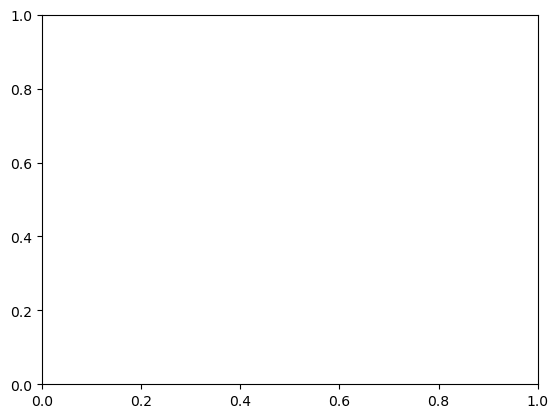

In [124]:
from random import randint

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# create empty lists for the x and y data
x = []
y = []

# create the figure and axes objects
fig, ax = plt.subplots()

# function that draws each frame of the animation
def animate(i):
    pt = randint(1,9) # grab a random integer to be the next y-value in the animation
    x.append(i)
    y.append(pt)

    ax.clear()
    ax.plot(x, y)
    ax.set_xlim([0,20])
    ax.set_ylim([0,10])

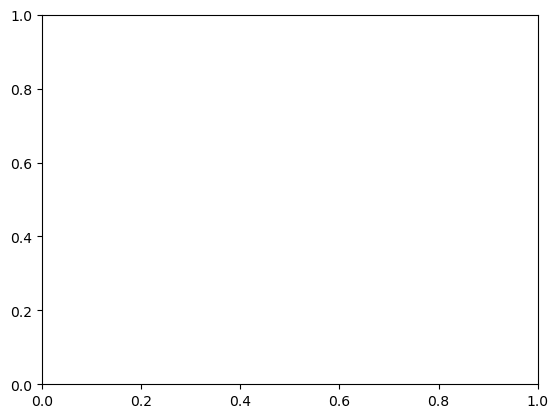

In [149]:
fig, ax = plt.subplots()
FuncAnimation(fig, animate, frames=10, interval=100, repeat=False)
plt.show()